# IVF search with spherical k-means

Compare a spherical k-means inverted-file index with exhaustive cosine search and the frozen random-hyperplane LSH baseline on the same medium fingerprints and CUDA device. The development split selects the IVF search budget. Held-out tracks report the final comparison.

The notebook expects the medium fingerprint archives produced by the medium pipeline. For the pinned LSH baseline, run once from the repository root in PowerShell:

```powershell
New-Item -ItemType Directory -Force data/review-baseline | Out-Null
New-Item -ItemType Directory -Force data/medium/cupy-cache | Out-Null
$source = 'https://raw.githubusercontent.com/ExoHumann/02807_computational_tools_ds/5e9427ee5f83cd32fdd9b5a1c8f40396c3772989/src/afp'
Invoke-WebRequest "$source/gpu_retrieval.py" -OutFile data/review-baseline/gpu_retrieval.py
Invoke-WebRequest "$source/gpu_lsh.cu" -OutFile data/review-baseline/gpu_lsh.cu
$env:AFP_FINGERPRINT_DIR = 'data/medium/data/processed/fingerprints'
$env:CUPY_CACHE_DIR = (Join-Path (Get-Location) 'data/medium/cupy-cache')
uv run --isolated --no-project --python 3.12 --with-requirements notebooks/requirements-ivf.txt jupyter nbconvert --execute --inplace --to notebook --ExecutePreprocessor.timeout=600 notebooks/ivf_medium.ipynb
```

Run all cells with the CUDA GPU that holds the medium fingerprint set in local storage. The search timings exclude data transfer and index construction.

In [1]:
from datetime import datetime, timezone
from pathlib import Path
from time import perf_counter, perf_counter_ns
import hashlib
import json
import os
import platform
import sys

import cupy as cp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src/afp/ivf.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from the repository or one of its child folders.")
DATA_DIR = Path(os.environ.get("AFP_FINGERPRINT_DIR", ROOT / "data/medium/data/processed/fingerprints"))
if not DATA_DIR.is_absolute():
    DATA_DIR = ROOT / DATA_DIR
BASELINE_DIR = ROOT / "data/review-baseline"
if not (BASELINE_DIR / "gpu_retrieval.py").is_file():
    raise FileNotFoundError(
        "Download gpu_retrieval.py and gpu_lsh.cu from PR #1 commit "
        "5e9427ee5f83cd32fdd9b5a1c8f40396c3772989 into data/review-baseline."
    )
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(BASELINE_DIR))
from afp.ivf import SphericalIVF
from gpu_retrieval import GPUAngularLSH, gpu_exact

OUT = ROOT / "reports"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
RESULT_PATH = OUT / "ivf-medium.json"
PNG_PATH = FIG / "ivf-medium.png"
PDF_PATH = FIG / "ivf-medium.pdf"

INPUTS = ("references.npz", "queries.npz", "queries_tiktok.npz")
missing = [f for f in INPUTS if not (DATA_DIR / f).is_file()]
if missing:
    raise FileNotFoundError(f"Missing medium fingerprint archives under {DATA_DIR}: {missing}")
def read_archive(name):
    with np.load(DATA_DIR / name, allow_pickle=False) as archive:
        return {key: archive[key] for key in archive.files}
def file_sha256(path):
    with path.open("rb") as source:
        return hashlib.file_digest(source, "sha256").hexdigest()

reference_data = read_archive("references.npz")
standard_data = read_archive("queries.npz")
tiktok_data = read_archive("queries_tiktok.npz")
references = np.ascontiguousarray(reference_data["vectors"], dtype=np.float32)
reference_tracks = np.ascontiguousarray(reference_data["track_id"], dtype=np.int32)
standard = np.ascontiguousarray(standard_data["vectors"], dtype=np.float32)
standard_tracks = np.ascontiguousarray(standard_data["track_id"], dtype=np.int32)
standard_labels = standard_data["augmentation"].astype(str)
tiktok = np.ascontiguousarray(tiktok_data["vectors"], dtype=np.float32)
tiktok_tracks = np.ascontiguousarray(tiktok_data["track_id"], dtype=np.int32)
tiktok_labels = tiktok_data["augmentation"].astype(str)
for name, vectors, tracks, labels in (
    ("references", references, reference_tracks, None),
    ("standard", standard, standard_tracks, standard_labels),
    ("TikTok-like", tiktok, tiktok_tracks, tiktok_labels),
):
    if vectors.ndim != 2 or vectors.shape[1] != 256 or tracks.shape != (len(vectors),):
        raise ValueError(f"Unexpected {name} fingerprint shape.")
    if labels is not None and labels.shape != tracks.shape:
        raise ValueError(f"Unexpected {name} distortion labels.")
    if not np.isfinite(vectors).all() or not np.allclose(np.linalg.norm(vectors, axis=1), 1, atol=2e-4):
        raise ValueError(f"{name} fingerprints must be finite and unit norm.")

DEV_SEED = 2211
INDEX_SEED = 2807
UNKNOWN_DEV_TOLERANCE = 0.005
CLUSTERS = (64, 256, 1024)
PROBES = (1, 4, 16)
MAX_ITER = int(os.environ.get("AFP_IVF_MAX_ITER", "20"))
DEV_TIME_QUERIES = 64
FINAL_TIME_QUERIES = 256
BATCH_SIZE = 128
BATCH_REPEATS = 4

dev_tracks = np.random.default_rng(DEV_SEED).choice(
    np.unique(standard_tracks), size=len(np.unique(standard_tracks)) // 4, replace=False
)
dev_mask = np.isin(standard_tracks, dev_tracks)
dev_queries = standard[dev_mask]
dev_truth = standard_tracks[dev_mask]
heldout_parts = []
for query_set, vectors, tracks, labels in (
    ("Standard", standard, standard_tracks, standard_labels),
    ("TikTok-like", tiktok, tiktok_tracks, tiktok_labels),
):
    keep = ~np.isin(tracks, dev_tracks)
    heldout_parts.append((query_set, vectors[keep], tracks[keep], labels[keep]))
heldout = np.ascontiguousarray(np.concatenate([part[1] for part in heldout_parts]), dtype=np.float32)
heldout_truth = np.concatenate([part[2] for part in heldout_parts]).astype(np.int32)
heldout_meta = pd.concat([
    pd.DataFrame({"query_set": name, "distortion": labels})
    for name, _, _, labels in heldout_parts
], ignore_index=True)
if np.intersect1d(dev_tracks, heldout_truth).size:
    raise AssertionError("A development track appears in held-out queries.")
input_info = {
    name: {"bytes": int((DATA_DIR / name).stat().st_size), "sha256": file_sha256(DATA_DIR / name)}
    for name in INPUTS
}
print(f"Python {platform.python_version()} · CuPy {cp.__version__}")
print(f"{len(references):,} reference windows · {np.unique(reference_tracks).size:,} tracks")
print(f"{len(dev_queries):,} standard development queries · {len(heldout):,} held-out queries")
display(pd.DataFrame([
    {"set": name, "held-out queries": int(np.sum(heldout_meta.query_set == name))}
    for name in ("Standard", "TikTok-like")
]))

E:\DevPro\CompToolsProject\02807_computational_tools_ds\.venv\Lib\site-packages\cupy\_environment.py:286: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


Python 3.12.11 · CuPy 14.2.0
110,320 reference windows · 24,970 tracks
2,542 standard development queries · 16,450 held-out queries


,set,held-out queries
0,Standard,7458
1,TikTok-like,8992


## GPU setup and frozen baselines

Exact search scans all reference windows. The LSH baseline is frozen at 10 bits, 64 tables and 3 extra probes per table from the earlier development result. IVF trains centroids on the reference vectors and probes the nearest centroids.

The timing includes search with reference vectors and index already resident on the GPU. Index fitting/building and first-call CUDA compilation are reported separately.

In [2]:
device = cp.cuda.Device()
props = cp.cuda.runtime.getDeviceProperties(device.id)
gpu_name = props["name"].decode(errors="replace") if isinstance(props["name"], bytes) else str(props["name"])
def synchronize():
    cp.cuda.runtime.deviceSynchronize()
references_gpu = cp.ascontiguousarray(cp.asarray(references))
reference_tracks_gpu = cp.asarray(reference_tracks)
dev_gpu = cp.ascontiguousarray(cp.asarray(dev_queries))
heldout_gpu = cp.ascontiguousarray(cp.asarray(heldout))
print(f"GPU: {gpu_name} · compute capability {device.compute_capability}")
print(f"Reference and query vectors stay in VRAM during the search timings.")

GPU: NVIDIA GeForce RTX 4090 · compute capability 89
Reference and query vectors stay in VRAM during the search timings.


## Compile and establish the baselines

LSH settings are fixed from the previous accuracy-first development result. The LSH index and exact baseline use the same references, query split, FP32 arithmetic and CUDA device as IVF.

In [3]:
compile_started = perf_counter()
warm_n = min(2048, len(references_gpu))
warm_ivf = SphericalIVF(
    references_gpu[:warm_n], reference_tracks_gpu[:warm_n],
    n_clusters=min(16, warm_n), seed=INDEX_SEED, max_iter=3,
)
warm_ivf.search(dev_gpu[:1], nprobe=min(4, warm_ivf.n_clusters))
warm_lsh = GPUAngularLSH(references_gpu[:warm_n], reference_tracks_gpu[:warm_n],
                         bits=10, tables=4, seed=INDEX_SEED)
warm_lsh.search(dev_gpu[:1], probes=1)
gpu_exact(references_gpu, reference_tracks_gpu, dev_gpu[:1])
synchronize()
compile_and_warm_seconds = perf_counter() - compile_started
del warm_ivf, warm_lsh

lsh_started = perf_counter()
lsh = GPUAngularLSH(references_gpu, reference_tracks_gpu, bits=10, tables=64, seed=INDEX_SEED)
synchronize()
lsh_build_seconds = perf_counter() - lsh_started
lsh_index_bytes = int(lsh.planes.nbytes + lsh.order.nbytes + lsh.offsets.nbytes)
dev_exact_gpu, dev_exact_scores = gpu_exact(references_gpu, reference_tracks_gpu, dev_gpu)
dev_lsh_gpu, dev_lsh_scores, dev_lsh_visits = lsh.search(dev_gpu, probes=3)
synchronize()
dev_exact = dev_exact_gpu.get()
dev_lsh = dev_lsh_gpu.get()
dev_lsh_accuracy = float(np.mean(dev_lsh == dev_truth))
dev_exact_accuracy = float(np.mean(dev_exact == dev_truth))
print(f"Development accuracy · exact {dev_exact_accuracy:.3%} · LSH {dev_lsh_accuracy:.3%}")
print(f"Frozen LSH build time: {lsh_build_seconds:.3f} s · compile and warm-up: {compile_and_warm_seconds:.3f} s")

Development accuracy · exact 97.758% · LSH 97.758%
Frozen LSH build time: 0.032 s · compile and warm-up: 0.250 s


## Spherical k-means IVF sweep

For each cluster count, spherical Lloyd iterations assign each unit vector to its most similar centroid, then normalize the mean direction of each cluster. At query time, IVF scans the 1, 4 or 16 most similar cluster lists and reranks those reference windows by exact cosine similarity.

The IVF setting is selected from standard development tracks only: fastest median single-query latency among settings within 0.5 percentage points of exact development accuracy. If none qualifies, highest development accuracy wins, with latency breaking ties.

In [4]:
def timed_single(reference_queries, order, methods):
    values = {name: [] for name in methods}
    for query_index in order:
        sequence = list(methods)
        np.random.default_rng(2807 + int(query_index)).shuffle(sequence)
        for name in sequence:
            synchronize()
            started = perf_counter_ns()
            methods[name](reference_queries[query_index:query_index + 1])
            synchronize()
            values[name].append((perf_counter_ns() - started) / 1e6)
    return {name: np.asarray(samples) for name, samples in values.items()}

dev_order = np.random.default_rng(20261122).choice(
    len(dev_queries), size=min(DEV_TIME_QUERIES, len(dev_queries)), replace=False
)
exact_dev_method = lambda q: gpu_exact(references_gpu, reference_tracks_gpu, q)
rows = []
indices = {}
pool = cp.get_default_memory_pool()
for cluster_count in CLUSTERS:
    memory_before = pool.used_bytes()
    build_started = perf_counter()
    index = SphericalIVF(
        references_gpu, reference_tracks_gpu, n_clusters=cluster_count,
        seed=INDEX_SEED, max_iter=MAX_ITER, fit_chunk_size=8192,
    )
    synchronize()
    build_seconds = perf_counter() - build_started
    allocated_delta = max(0, pool.used_bytes() - memory_before)
    indices[cluster_count] = index
    for probe_count in PROBES:
        predicted_gpu, scores_gpu, visits_gpu = index.search(dev_gpu, nprobe=probe_count, validate=False)
        synchronize()
        predicted, scores, visits = predicted_gpu.get(), scores_gpu.get(), visits_gpu.get()
        if np.any(scores > dev_exact_scores.get() + 2e-5):
            raise AssertionError("IVF exceeded the exhaustive cosine score beyond tolerance.")
        timings = timed_single(dev_gpu, dev_order, {
            "exact": exact_dev_method,
            "ivf": lambda q, current=index, p=probe_count: current.search(q, nprobe=p, validate=False),
        })
        rows.append({
            "clusters": cluster_count,
            "probes": probe_count,
            "dev_accuracy": float(np.mean(predicted == dev_truth)),
            "dev_exact_agreement": float(np.mean(predicted == dev_exact)),
            "mean_window_visits": float(visits.mean()),
            "visit_fraction": float(visits.mean() / len(references)),
            "build_seconds": float(build_seconds),
            "training_iterations": int(index.iterations),
            "index_bytes": int(index.index_bytes),
            "fit_allocated_delta_bytes": int(allocated_delta),
            "dev_exact_median_ms": float(np.median(timings["exact"])),
            "dev_ivf_median_ms": float(np.median(timings["ivf"])),
            "dev_ivf_p95_ms": float(np.percentile(timings["ivf"], 95)),
            "dev_timing_queries": int(len(dev_order)),
        })
        del predicted_gpu, scores_gpu, visits_gpu, predicted, scores, visits
    print(f"{cluster_count} centroids fitted in {index.iterations} iterations · {build_seconds:.2f} s")

sweep = pd.DataFrame(rows)
eligible = sweep[sweep.dev_accuracy >= dev_exact_accuracy - UNKNOWN_DEV_TOLERANCE]
if len(eligible):
    selected = eligible.sort_values(["dev_ivf_median_ms", "mean_window_visits", "clusters", "probes"]).iloc[0]
    selection_rule = "fastest within 0.5 percentage points of exact development accuracy"
else:
    selected = sweep.sort_values(["dev_accuracy", "dev_ivf_median_ms"], ascending=[False, True]).iloc[0]
    selection_rule = "highest development accuracy, then fastest latency"
selected_clusters, selected_probes = int(selected.clusters), int(selected.probes)
selected_index = indices[selected_clusters]
display(sweep.sort_values(["clusters", "probes"]).round(5))
display(Markdown(
    f"**Selected IVF:** {selected_clusters} clusters, {selected_probes} probes; "
    f"development accuracy {selected.dev_accuracy:.2%} versus exact {dev_exact_accuracy:.2%}."
))

64 centroids fitted in 20 iterations · 0.05 s


256 centroids fitted in 20 iterations · 0.08 s


1024 centroids fitted in 20 iterations · 0.10 s


,clusters,probes,dev_accuracy,dev_exact_agreement,mean_window_visits,visit_fraction,build_seconds,training_iterations,index_bytes,fit_allocated_delta_bytes,dev_exact_median_ms,dev_ivf_median_ms,dev_ivf_p95_ms,dev_timing_queries
0,64,1,0.82809,0.84146,1773.68135,0.01608,0.04521,20,507076,507392,0.19835,0.12455,0.14515,64
1,64,4,0.96341,0.98426,6974.60582,0.06322,0.04521,20,507076,507392,0.19435,0.13320,0.15898,64
2,64,16,0.97718,0.99921,27472.22974,0.24902,0.04521,20,507076,507392,0.18270,0.14065,0.16129,64
3,256,1,0.74744,0.76082,447.99410,0.00406,0.07583,20,704452,705024,0.19840,0.07850,0.37787,64
4,256,4,0.93548,0.95319,1760.94060,0.01596,0.07583,20,704452,705024,0.19625,0.07780,0.14500,64
5,256,16,0.97325,0.99489,6851.72935,0.06211,0.07583,20,704452,705024,0.19395,0.07890,0.09502,64
6,1024,1,0.75649,0.76908,115.95004,0.00105,0.10074,20,1493956,1494528,0.19945,0.07180,0.07873,64
7,1024,4,0.92644,0.94296,458.26318,0.00415,0.10074,20,1493956,1494528,0.20000,0.06785,0.21464,64
8,1024,16,0.96656,0.98741,1777.64241,0.01611,0.10074,20,1493956,1494528,0.19675,0.06705,0.21266,64


**Selected IVF:** 256 clusters, 16 probes; development accuracy 97.32% versus exact 97.76%.

## Held-out retrieval accuracy and speed

The development tracks are excluded from both held-out query sets. Reported accuracy counts a result correct when its predicted song ID equals the source song ID.

In [5]:
exact_heldout = []
exact_scores_heldout = []
lsh_heldout = []
lsh_scores_heldout = []
lsh_visits_heldout = []
ivf_heldout = []
ivf_scores_heldout = []
ivf_visits_heldout = []
for start in range(0, len(heldout), 256):
    query_chunk = heldout_gpu[start:start + 256]
    exact_ids, exact_scores = gpu_exact(references_gpu, reference_tracks_gpu, query_chunk)
    lsh_ids, lsh_scores, lsh_visits = lsh.search(query_chunk, probes=3)
    ivf_ids, ivf_scores, ivf_visits = selected_index.search(query_chunk, nprobe=selected_probes, validate=False)
    exact_heldout.append(exact_ids.get())
    exact_scores_heldout.append(exact_scores.get())
    lsh_heldout.append(lsh_ids.get())
    lsh_scores_heldout.append(lsh_scores.get())
    lsh_visits_heldout.append(lsh_visits.get())
    ivf_heldout.append(ivf_ids.get())
    ivf_scores_heldout.append(ivf_scores.get())
    ivf_visits_heldout.append(ivf_visits.get())
exact_heldout = np.concatenate(exact_heldout)
exact_scores_heldout = np.concatenate(exact_scores_heldout)
lsh_heldout = np.concatenate(lsh_heldout)
lsh_scores_heldout = np.concatenate(lsh_scores_heldout)
lsh_visits_heldout = np.concatenate(lsh_visits_heldout)
ivf_heldout = np.concatenate(ivf_heldout)
ivf_scores_heldout = np.concatenate(ivf_scores_heldout)
ivf_visits_heldout = np.concatenate(ivf_visits_heldout)
if np.any(ivf_scores_heldout > exact_scores_heldout + 2e-5):
    raise AssertionError("IVF exceeded exhaustive cosine search.")

method_predictions = {"Exact": exact_heldout, "Frozen LSH": lsh_heldout, "IVF": ivf_heldout}
closed_rows = []
for query_set in ("Standard", "TikTok-like"):
    mask = heldout_meta.query_set.to_numpy() == query_set
    for method, prediction in method_predictions.items():
        closed_rows.append({
            "query_set": query_set, "method": method, "queries": int(mask.sum()),
            "track_accuracy": float(np.mean(prediction[mask] == heldout_truth[mask])),
        })
closed = pd.DataFrame(closed_rows)
display(closed.pivot(index="query_set", columns="method", values="track_accuracy").round(4))

distortion_rows = []
for (query_set, distortion), group in heldout_meta.groupby(["query_set", "distortion"], sort=True):
    ids = group.index.to_numpy()
    for method, prediction in method_predictions.items():
        distortion_rows.append({
            "query_set": query_set, "distortion": distortion, "method": method,
            "queries": int(len(ids)),
            "track_accuracy": float(np.mean(prediction[ids] == heldout_truth[ids])),
        })
distortion_table = pd.DataFrame(distortion_rows)
display(distortion_table.pivot(index=["query_set", "distortion"], columns="method", values="track_accuracy").round(3))

method,Exact,Frozen LSH,IVF
query_set,,,
Standard,0.9808,0.9808,0.9753
TikTok-like,0.9354,0.9354,0.9277


method                                       Exact  Frozen LSH    IVF
query_set   distortion                                               
Standard    band_pass                        0.983       0.983  0.977
            echo                             0.985       0.985  0.982
            high_pass                        0.989       0.989  0.984
            low_pass                         0.989       0.989  0.989
            noise                            0.966       0.966  0.959
            pitch_shift                      0.985       0.985  0.977
            reverb                           0.984       0.984  0.981
            reverb+noise                     0.966       0.966  0.958
            time_stretch                     0.984       0.984  0.983
            time_stretch+pitch_shift         0.978       0.978  0.964
TikTok-like compression                      0.986       0.986  0.984
            speed_up                         0.973       0.973  0.962
            speed_up+voice_over+compression  0.792       0.792  0.779
            voice_over                       0.973       0.973  0.966

## Synchronized timing

Single-query timing uses the same sampled queries in randomized method order, with the CUDA device synchronized around each call. Batch throughput uses 128-query chunks and four alternating repetitions. These measurements exclude file loading, host-to-device upload, model inference and index building.

In [6]:
heldout_order = np.random.default_rng(4422).choice(
    len(heldout), size=min(FINAL_TIME_QUERIES, len(heldout)), replace=False
)
exact_method = lambda q: gpu_exact(references_gpu, reference_tracks_gpu, q)
lsh_method = lambda q: lsh.search(q, probes=3)
ivf_method = lambda q: selected_index.search(q, nprobe=selected_probes, validate=False)
single_times = timed_single(heldout_gpu, heldout_order, {
    "exact": exact_method, "lsh": lsh_method, "ivf": ivf_method,
})
timing_summary = {
    method: {"median_ms": float(np.median(values)), "p95_ms": float(np.percentile(values, 95))}
    for method, values in single_times.items()
}
batch_methods = {"exact": exact_method, "lsh": lsh_method, "ivf": ivf_method}
batch_seconds = {name: [] for name in batch_methods}
warm_chunk = heldout_gpu[:BATCH_SIZE]
for method in batch_methods.values():
    method(warm_chunk)
synchronize()
for repeat in range(BATCH_REPEATS):
    order = list(batch_methods)
    if repeat % 2:
        order.reverse()
    for name in order:
        synchronize()
        started = perf_counter()
        for start in range(0, len(heldout_gpu), BATCH_SIZE):
            batch_methods[name](heldout_gpu[start:start + BATCH_SIZE])
        synchronize()
        batch_seconds[name].append(perf_counter() - started)
throughput = {
    name: {
        "median_seconds": float(np.median(samples)),
        "p95_seconds": float(np.percentile(samples, 95)),
        "median_queries_per_second": float(len(heldout) / np.median(samples)),
    } for name, samples in batch_seconds.items()
}
display(pd.DataFrame(timing_summary).T.round(4))
display(pd.DataFrame(throughput).T.round(2))

,median_ms,p95_ms
exact,0.1778,0.2072
lsh,0.0880,0.1146
ivf,0.0762,0.1633


,median_seconds,p95_seconds,median_queries_per_second
exact,0.05,0.05,359690.99
lsh,0.24,0.25,67186.53
ivf,0.04,0.04,448620.66


## Results and artifact

The figure contrasts held-out accuracy and warmed single-query latency for exact search, the previously selected LSH baseline and the development-selected IVF. The right panel shows the IVF development sweep. Results JSON records the sweep, provenance, index size and timings.

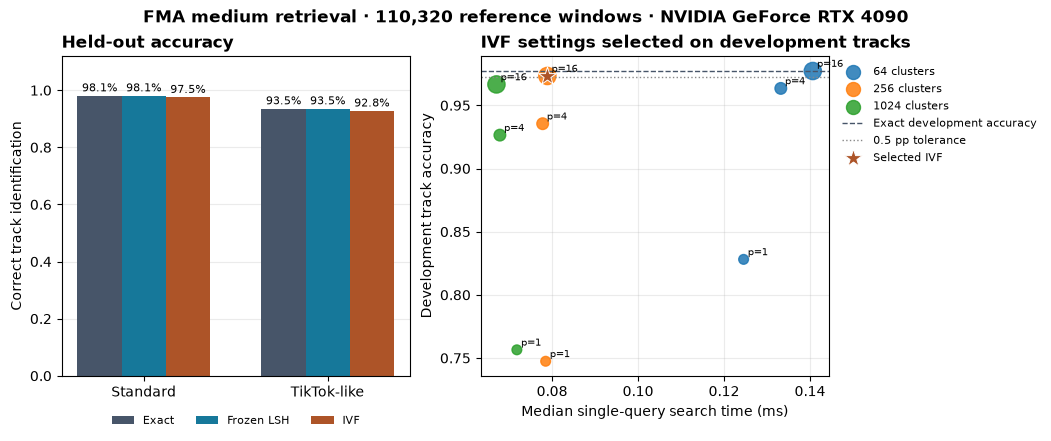

Saved reports\ivf-medium.json
Saved reports\figures\ivf-medium.png and reports\figures\ivf-medium.pdf


In [7]:
colors = {"Exact": "#475569", "Frozen LSH": "#16789A", "IVF": "#AD5428"}
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.3), layout="constrained")
sets = ("Standard", "TikTok-like")
methods = ("Exact", "Frozen LSH", "IVF")
x = np.arange(len(sets))
width = 0.24
for offset, method in enumerate(methods):
    values = [closed.loc[(closed.query_set == query_set) & (closed.method == method), "track_accuracy"].iloc[0]
              for query_set in sets]
    axes[0].bar(x + (offset - 1) * width, values, width, label=method, color=colors[method])
    for i, value in enumerate(values):
        axes[0].text(x[i] + (offset - 1) * width, value + .006, f"{value:.1%}",
                     ha="center", va="bottom", fontsize=8)
axes[0].set_xticks(x, sets)
axes[0].set_ylim(0, 1.12)
axes[0].set_ylabel("Correct track identification")
axes[0].set_title("Held-out accuracy", loc="left", fontweight="bold")
axes[0].legend(frameon=False, loc="lower center", bbox_to_anchor=(.5, -.19), ncol=3, fontsize=8)
axes[0].grid(axis="y", alpha=.25)
axes[0].set_axisbelow(True)

for clusters, group in sweep.groupby("clusters"):
    axes[1].scatter(group.dev_ivf_median_ms, group.dev_accuracy, s=42 + 7 * group.probes,
                    label=f"{clusters} clusters", alpha=.85)
    for row in group.itertuples():
        axes[1].annotate(f"p={row.probes}", (row.dev_ivf_median_ms, row.dev_accuracy),
                         xytext=(3, 3), textcoords="offset points", fontsize=7)
axes[1].axhline(dev_exact_accuracy, color="#475569", linestyle="--", linewidth=1,
                label="Exact development accuracy")
axes[1].axhline(dev_exact_accuracy - UNKNOWN_DEV_TOLERANCE, color="#888", linestyle=":",
                linewidth=1, label="0.5 pp tolerance")
axes[1].scatter([selected.dev_ivf_median_ms], [selected.dev_accuracy], marker="*", s=180,
                color="#AD5428", edgecolor="white", linewidth=.7, zorder=5, label="Selected IVF")
axes[1].set_xlabel("Median single-query search time (ms)")
axes[1].set_ylabel("Development track accuracy")
axes[1].set_title("IVF settings selected on development tracks", loc="left", fontweight="bold")
axes[1].grid(alpha=.25)
axes[1].set_axisbelow(True)
axes[1].legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.suptitle(f"FMA medium retrieval · {len(references):,} reference windows · {gpu_name}", fontweight="bold")
fig.savefig(PNG_PATH, dpi=220, bbox_inches="tight")
fig.savefig(PDF_PATH, bbox_inches="tight")
plt.show()

def records(frame):
    return json.loads(frame.to_json(orient="records"))
result = {
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "source_directory": "data/medium/data/processed/fingerprints",
    "input_files": input_info,
    "gpu": {"device": gpu_name, "compute_capability": str(device.compute_capability),
            "cupy": cp.__version__, "device_id": int(device.id)},
    "dataset": {
        "reference_windows": int(len(references)),
        "reference_tracks": int(np.unique(reference_tracks).size),
        "development_queries": int(len(dev_queries)),
        "development_tracks": int(len(dev_tracks)),
        "heldout_queries": int(len(heldout)),
        "heldout_by_set": {name: int(np.sum(heldout_meta.query_set == name)) for name in sets},
        "vector_dimension": 256,
    },
    "protocol": {
        "development_track_seed": DEV_SEED,
        "index_seed": INDEX_SEED,
        "development_accuracy_tolerance": UNKNOWN_DEV_TOLERANCE,
        "selection_rule": selection_rule,
        "heldout_tracks_exclude_development_tracks": True,
        "query_search_excludes_upload_and_index_build": True,
        "frozen_lsh": {"bits": 10, "tables": 64, "probes": 3},
        "kmeans_initialization": "seeded reference-vector sample",
        "kmeans_max_iterations": MAX_ITER,
    },
    "baselines": {
        "development_exact_accuracy": dev_exact_accuracy,
        "development_lsh_accuracy": dev_lsh_accuracy,
        "lsh_build_seconds": lsh_build_seconds,
        "heldout_closed": records(closed),
    },
    "development_sweep": records(sweep),
    "selected_ivf": {
        "clusters": selected_clusters, "probes": selected_probes,
        "development_accuracy": float(selected.dev_accuracy),
        "mean_window_visits": float(selected.mean_window_visits),
        "index_bytes": int(selected.index_bytes),
        "build_seconds": float(selected.build_seconds),
        "training_iterations": int(selected.training_iterations),
    },
    "heldout_by_distortion": records(distortion_table),
    "single_query_timing": timing_summary,
    "resident_batch_throughput": throughput,
    "index_footprint": {
        "ivf_bytes": int(selected.index_bytes),
        "frozen_lsh_bytes": int(lsh_index_bytes),
        "shared_reference_bytes": int(references.nbytes),
        "training_fit_chunk_size": 8192,
        "temporary_fit_similarity_bytes": int(8192 * max(CLUSTERS) * 4),
        "cuda_compile_and_warmup_seconds": float(compile_and_warm_seconds),
    },
    "figures": {"png": "reports/figures/ivf-medium.png", "pdf": "reports/figures/ivf-medium.pdf"},
    "limitations": [
        "Synthetic distortions do not represent all real phone recordings.",
        "Timing measures warmed retrieval with vectors and index already on the GPU.",
        "Spherical k-means starts from a seeded sample of reference vectors and uses bounded Lloyd iterations.",
    ],
}
RESULT_PATH.write_text(json.dumps(result, indent=2, allow_nan=False), encoding="utf-8")
print(f"Saved {RESULT_PATH.relative_to(ROOT)}")
print(f"Saved {PNG_PATH.relative_to(ROOT)} and {PDF_PATH.relative_to(ROOT)}")